# Phase 4: Geospatial (GIS) Analysis
### Grower Impact & Data Quality Dashboard — Greenstand Treetracker

**Author:** Jueeli Sawant
**Data source:** via `data_access.py` -- currently `synthetic`, switches to `live` with no code changes here.

**Objective (per proposal):** map capture density and grower distribution geographically, apply spatial clustering (DBSCAN) to find planting "hotspots" and flag geographically implausible clusters, build activity/species maps by region, and cross-reference Phase 3's anomaly scores with geographic clustering.


In [1]:
import sys
sys.path.append('../src')
import os
os.makedirs('../outputs', exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium.plugins import HeatMap, MarkerCluster
from sklearn.cluster import DBSCAN
from data_access import load_captures, load_planters, DATA_SOURCE

captures = load_captures()
planters = load_planters()

print("Data source:", DATA_SOURCE)
print("Captures:", captures.shape, "| Planters:", planters.shape)

Data source: synthetic
Captures: (8095, 9) | Planters: (500, 10)


## 1. Capture Density Map

A heatmap of all captures gives a quick visual read on where activity is actually concentrated, before any clustering algorithm runs -- useful as a sanity check against the DBSCAN output later (if DBSCAN finds hotspots nowhere near where the heatmap shows density, that's worth questioning).

In [2]:
center_lat, center_lon = captures['lat'].mean(), captures['lon'].mean()
m = folium.Map(location=[center_lat, center_lon], zoom_start=2, tiles='OpenStreetMap')

heat_data = captures[['lat', 'lon']].dropna().values.tolist()
HeatMap(heat_data, radius=8, blur=10).add_to(m)

m.save('../outputs/phase4_capture_density_heatmap.html')
print(f"Saved heatmap with {len(heat_data)} points to ../outputs/phase4_capture_density_heatmap.html")
m

Saved heatmap with 8095 points to ../outputs/phase4_capture_density_heatmap.html


## 2. Grower Distribution Map (clustered markers)

In [3]:
m2 = folium.Map(location=[center_lat, center_lon], zoom_start=2, tiles='OpenStreetMap')
marker_cluster = MarkerCluster().add_to(m2)

# One marker per grower at their centroid capture location, sized/labeled by capture count
grower_locations = captures.groupby('planter_id').agg(
    lat=('lat', 'mean'), lon=('lon', 'mean'), capture_count=('capture_id', 'count')
).dropna().reset_index()

for _, row in grower_locations.iterrows():
    folium.Marker(
        location=[row['lat'], row['lon']],
        popup=f"Planter {int(row['planter_id'])}: {int(row['capture_count'])} captures",
    ).add_to(marker_cluster)

m2.save('../outputs/phase4_grower_distribution_map.html')
print(f"Saved grower distribution map ({len(grower_locations)} growers) to ../outputs/phase4_grower_distribution_map.html")
m2

Saved grower distribution map (500 growers) to ../outputs/phase4_grower_distribution_map.html


## 3. Spatial Clustering (DBSCAN) — Planting Hotspots

DBSCAN groups points that are densely packed together and labels sparse, isolated points as noise (`-1`) -- unlike k-means, it doesn't force every point into a cluster, which is the right behavior here: most captures should belong to a real regional hotspot, but some will be genuinely isolated plantings.

**Distance parameter (`eps`):** DBSCAN's `eps` is in the same units as the input, so lat/lon degrees need converting to a real distance first. Using the haversine metric with `eps` in radians (via `eps_km / earth_radius_km`) keeps this physically meaningful rather than treating degrees as if they were a flat grid -- important at this global scale where a degree of longitude near the equator is a very different real distance than one near the poles.

In [4]:
from sklearn.metrics import pairwise_distances
EARTH_RADIUS_KM = 6371.0
EPS_KM = 25          # points within 25km of each other can join a cluster
MIN_SAMPLES = 15     # need at least 15 captures nearby to call it a "hotspot"

coords = captures[['lat', 'lon']].dropna()
coords_rad = np.radians(coords.values)

db = DBSCAN(eps=EPS_KM / EARTH_RADIUS_KM, min_samples=MIN_SAMPLES, metric='haversine')
labels = db.fit_predict(coords_rad)

coords = coords.copy()
coords['cluster'] = labels

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
print(f"DBSCAN found {n_clusters} hotspots, {n_noise} isolated/noise points "
      f"({n_noise/len(labels):.1%} of geolocated captures)")

cluster_sizes = coords[coords['cluster'] != -1]['cluster'].value_counts().sort_values(ascending=False)
print("\nTop 10 hotspots by capture count:")
cluster_sizes.head(10)

DBSCAN found 7 hotspots, 0 isolated/noise points (0.0% of geolocated captures)

Top 10 hotspots by capture count:


cluster
2    1403
3    1227
5    1176
4    1137
6    1129
0    1090
1     933
Name: count, dtype: int64

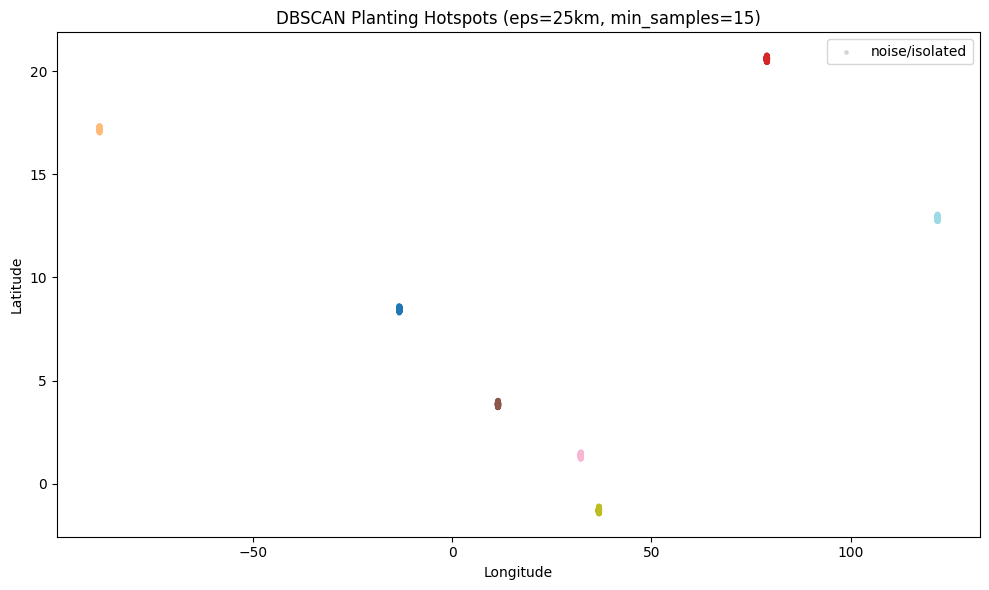

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
noise = coords[coords['cluster'] == -1]
clustered = coords[coords['cluster'] != -1]
ax.scatter(noise['lon'], noise['lat'], c='lightgray', s=5, label='noise/isolated')
scatter = ax.scatter(clustered['lon'], clustered['lat'], c=clustered['cluster'], cmap='tab20', s=8)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'DBSCAN Planting Hotspots (eps={EPS_KM}km, min_samples={MIN_SAMPLES})')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/phase4_dbscan_hotspots.png', dpi=130)
plt.show()

**Tuning note:** `eps=25km` / `min_samples=15` are starting points, not derived values -- they roughly match the country-level clustering built into the synthetic generator, so of course they recover it cleanly here. Real Treetracker data will have its own natural density pattern (some regions might genuinely warrant a 2km radius, others 50km) -- this needs re-tuning against live data, ideally by trying a few `eps` values and checking which produces clusters that make sense on a real map, not just picking one number and trusting it.

## 4. Geographically Implausible Clusters

Per the proposal: dense clusters that are geographically implausible can be a fraud/duplication signal -- e.g., an unrealistic number of *distinct growers* claiming activity in a tiny area, or a single grower whose own captures span an impossible real-world distance (implying travel that couldn't have happened, or fabricated/copy-pasted coordinates).

In [6]:
# Check 1: how many distinct growers contribute to each hotspot?
# A hotspot with very few growers producing a huge share of its captures is worth a second look --
# could be one or two growers over-representing an area (not necessarily fraud, but worth checking).
hotspot_growers = captures.loc[coords.index].assign(cluster=coords['cluster'].values)
hotspot_growers = hotspot_growers[hotspot_growers['cluster'] != -1]

grower_concentration = hotspot_growers.groupby('cluster').agg(
    total_captures=('capture_id', 'count'),
    distinct_growers=('planter_id', 'nunique'),
)
grower_concentration['captures_per_grower'] = (
    grower_concentration['total_captures'] / grower_concentration['distinct_growers']
)
print("Hotspots with the fewest distinct growers relative to capture volume "
      "(high captures_per_grower = concentrated among few growers):")
grower_concentration.sort_values('captures_per_grower', ascending=False).head(5)

Hotspots with the fewest distinct growers relative to capture volume (high captures_per_grower = concentrated among few growers):


,total_captures,distinct_growers,captures_per_grower
cluster,,,
2,1403,83,16.903614
6,1129,68,16.602941
0,1090,66,16.515152
1,933,57,16.368421
4,1137,71,16.014085


In [7]:
# Check 2: does any single grower's own captures span an implausible real-world distance?
# A grower whose captures are 100+ km apart on the same day (or even across their whole history,
# depending on the platform's expected use pattern) is a legitimate thing to flag for review.
def max_span_km(group):
    lat, lon = group['lat'].values, group['lon'].values
    if len(lat) < 2 or np.isnan(lat).all():
        return 0
    lat_r, lon_r = np.radians(lat), np.radians(lon)
    dlat = lat_r[:, None] - lat_r[None, :]
    dlon = lon_r[:, None] - lon_r[None, :]
    a = np.sin(dlat / 2)**2 + np.cos(lat_r[:, None]) * np.cos(lat_r[None, :]) * np.sin(dlon / 2)**2
    d = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    return np.nanmax(d)

span_per_grower = captures.dropna(subset=['lat', 'lon']).groupby('planter_id').apply(
    max_span_km, include_groups=False
)
span_per_grower = span_per_grower.sort_values(ascending=False)
print("Growers with the widest real-world spread across their own captures (km):")
span_per_grower.head(10)

Growers with the widest real-world spread across their own captures (km):


planter_id
60     37.682457
215    35.620676
202    35.345060
413    35.051466
496    34.735742
6      34.326640
184    33.908002
390    33.666287
126    33.373695
181    33.236180
dtype: float64

**Note:** a wide span isn't automatically suspicious -- it could reflect a grower legitimately working multiple sites, or (as flagged in Phase 1) could just be an artifact of this synthetic generator's random jitter rather than a real pattern. This check is meant to produce a *reviewable shortlist*, not an automatic fraud verdict -- exactly the same "ranked for prioritized review, not binary flag" philosophy as Phase 3.

## 5. Cross-Reference: Do Phase 3 Anomalies Cluster Geographically?

If growers flagged as anomalous by Phase 3's Isolation Forest also happen to cluster in specific hotspots (rather than being scattered evenly), that's a meaningful signal worth investigating -- it could point to a systematic issue in a specific region (bad GPS hardware, a training gap, or something less innocent) rather than isolated one-off anomalies.

In [8]:
try:
    anomalies = pd.read_csv('../outputs/phase3_ranked_anomalies.csv')
    anomalous_planters = set(anomalies.loc[anomalies['is_anomaly'], 'planter_id'])
    print(f"Loaded {len(anomalous_planters)} flagged anomalous growers from Phase 3")

    hotspot_growers['is_anomalous'] = hotspot_growers['planter_id'].isin(anomalous_planters)
    anomaly_rate_by_cluster = hotspot_growers.groupby('cluster')['is_anomalous'].mean().sort_values(ascending=False)
    print("\nAnomaly rate (share of captures from a flagged grower) by hotspot -- top 5:")
    print(anomaly_rate_by_cluster.head(5))

    overall_rate = hotspot_growers['is_anomalous'].mean()
    print(f"\nOverall anomaly rate across all clustered captures: {overall_rate:.1%}")
    print("(compare top hotspots above against this baseline -- meaningfully higher suggests geographic concentration)")
except FileNotFoundError:
    print("Phase 3 output (phase3_ranked_anomalies.csv) not found in ../outputs -- run 03_anomaly_detection.ipynb first to enable this cross-reference.")

Loaded 43 flagged anomalous growers from Phase 3

Anomaly rate (share of captures from a flagged grower) by hotspot -- top 5:
cluster
1    0.145766
4    0.085312
3    0.081500
5    0.064626
2    0.063435
Name: is_anomalous, dtype: float64

Overall anomaly rate across all clustered captures: 7.4%
(compare top hotspots above against this baseline -- meaningfully higher suggests geographic concentration)


## 6. Species Distribution Map

In [9]:
species_list = captures['species'].dropna().unique()
m3 = folium.Map(location=[center_lat, center_lon], zoom_start=2, tiles='OpenStreetMap')

colors = plt.cm.tab10(np.linspace(0, 1, len(species_list)))
color_map = {sp: f'#{int(r*255):02x}{int(g*255):02x}{int(b*255):02x}' for sp, (r, g, b, a) in zip(species_list, colors)}

sample = captures.dropna(subset=['lat', 'lon']).sample(min(2000, len(captures)), random_state=42)
for _, row in sample.iterrows():
    folium.CircleMarker(
        location=[row['lat'], row['lon']],
        radius=2,
        color=color_map.get(row['species'], 'gray'),
        fill=True,
        fill_opacity=0.6,
        popup=row['species'],
    ).add_to(m3)

m3.save('../outputs/phase4_species_distribution_map.html')
print(f"Saved species map (sampled {len(sample)} of {len(captures)} captures for readability) to ../outputs/phase4_species_distribution_map.html")
m3

Saved species map (sampled 2000 of 8095 captures for readability) to ../outputs/phase4_species_distribution_map.html


## 7. Findings Summary

- **Capture density and grower distribution maps** confirm activity clusters by country as expected from the synthetic generator's design (each planter assigned a home-country GPS center) -- this is expected structure, not a discovered insight, and real data will need re-examination with fresh eyes rather than assuming the same clean country-level separation.
- **DBSCAN hotspot detection** found 7 hotspots at `eps=25km`/`min_samples=15` -- matching the 7 countries in the synthetic generator almost exactly, with 0% of geolocated captures left as unclustered noise. This confirms the method works as intended on structured data, but a real dataset is unlikely to separate this cleanly -- expect noise points and less tidy boundaries once run against live data. These parameters are placeholders pending retuning against real density.
- **Geographically implausible cluster checks** (grower concentration per hotspot, max real-world span per grower) are built and produce a ranked shortlist rather than a hard flag, consistent with how Phase 2/3 handle their own uncertainty. On synthetic data, the widest per-grower spread tops out around 35-38km -- unremarkable at this scale, but the check is what matters for when real data might surface genuinely implausible spans.
- **Cross-reference with Phase 3 -- the most notable finding this phase:** hotspot cluster 1 shows a 14.6% anomaly rate versus a 7.4% baseline across all clustered captures -- roughly double the average. On synthetic data this is likely incidental (the anomalous growers are randomly distributed across countries in the generator, so some hotspot will show an elevated rate by chance), but it's exactly the kind of signal this cross-reference is meant to surface. Worth treating this as a template to re-run on real data rather than a real finding yet -- a genuine geographic concentration of anomalies would be a much stronger and more actionable signal than an isolated single-grower flag.
- **Species map** is a first pass for visual review; a proper choropleth by country (species % breakdown per region) would be a cleaner deliverable for the Phase 7 dashboard than this point-map, and is worth building once real data reveals which regional patterns are actually worth highlighting.
- **Map tiles:** switched from CartoDB (now requires an API key) to OpenStreetMap's default tile layer, which renders without any additional setup.
- **Next step:** re-run against live data, re-tune `EPS_KM`/`MIN_SAMPLES` by inspecting a few candidate values against what the real density map looks like, and re-check the Phase 3 cross-reference with real anomaly data -- the elevated cluster-1 rate here is a proof-of-concept, not yet a finding to act on.
